# HV-009 — Dynamic Tracking

**Technical gate:** DT-001  
**Dataset release:** VSM-LAB-DATA-v1.1

This notebook evaluates continuously varying RH behavior under:

- ramp excitation;
- repeated cyclic excitation;
- sinusoidal excitation.

The frozen C1 calibration remains unchanged throughout this milestone.

## 1. Engineering Question

> How accurately does the RH DUT track time-varying humidity after frozen static calibration, and what dynamic hysteresis, drift, gain attenuation, and phase lag remain?

HV-009 extends the step-response evidence from HV-008 into continuous dynamic operation.

## 2. Reproducible Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

current_dir = Path.cwd()
candidate_roots = [current_dir, *current_dir.parents]

project_root = next(
    (
        path
        for path in candidate_roots
        if (path / "data" / "raw" / "vsm_lab_data_v1_1").exists()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate project root containing "
        "'data/raw/vsm_lab_data_v1_1'."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.dynamic_tracking_analysis import (
    cyclic_cycle_metrics,
    cyclic_session_summary,
    load_dynamic_tracking,
    load_frozen_c1_offset,
    ramp_metrics_table,
    sinusoidal_frequency_response,
)

tables_dir = project_root / "reports" / "tables"
figures_dir = project_root / "reports" / "figures"
tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

print(f"Project root: {project_root}")

Project root: /home/runner/work/hvac-sensor-validation-metrology/hvac-sensor-validation-metrology


## 3. DT-01 — Dynamic Dataset Boundary Audit

Expected frozen release boundaries:

- Ramp: 18 Test_IDs, 21,618 rows;
- Cyclic: 3 Test_IDs, 9,003 rows;
- Sinusoidal: 4 Test_IDs, 5,404 rows.

No static/calibration/validation observations are used to create dynamic models here.

In [2]:
ramp_df, cyclic_df, sinusoidal_df, test_matrix_df = load_dynamic_tracking(project_root)

print("Ramp")
print(f"  rows      : {len(ramp_df)}")
print(f"  Test_IDs  : {ramp_df['Test_ID'].nunique()}")
print(f"  samples/Test_ID: {sorted(ramp_df.groupby('Test_ID').size().unique().tolist())}")

print("\nCyclic")
print(f"  rows      : {len(cyclic_df)}")
print(f"  Test_IDs  : {cyclic_df['Test_ID'].nunique()}")
print(f"  samples/Test_ID: {sorted(cyclic_df.groupby('Test_ID').size().unique().tolist())}")
print(f"  cycles    : {sorted(cyclic_df['Cycle_Index'].unique().tolist())}")

print("\nSinusoidal")
print(f"  rows      : {len(sinusoidal_df)}")
print(f"  Test_IDs  : {sinusoidal_df['Test_ID'].nunique()}")
print(f"  periods s : {sorted(sinusoidal_df['Period_s'].unique().tolist())}")
print(f"  frequencies Hz: {sorted(sinusoidal_df['Frequency_Hz'].unique().tolist())}")

assert len(ramp_df) == 21618
assert ramp_df["Test_ID"].nunique() == 18
assert len(cyclic_df) == 9003
assert cyclic_df["Test_ID"].nunique() == 3
assert len(sinusoidal_df) == 5404
assert sinusoidal_df["Test_ID"].nunique() == 4

assert sorted(ramp_df["Temperature_Setpoint_C"].unique().tolist()) == [15.0, 25.0, 35.0]
assert set(ramp_df["Direction"].astype(str).str.upper().unique()) == {"UP", "DOWN"}
assert sorted(ramp_df["Repetition"].unique().tolist()) == [1, 2, 3]

assert sorted(cyclic_df["Cycle_Index"].unique().tolist()) == [1, 2, 3, 4, 5]
assert np.allclose(cyclic_df["Temperature_Setpoint_C"].unique(), [25.0])

assert sorted(sinusoidal_df["Period_s"].unique().tolist()) == [60, 120, 300, 600]

print("\nDT-01 dataset boundary audit: PASS")

Ramp
  rows      : 21618
  Test_IDs  : 18
  samples/Test_ID: [1201]

Cyclic
  rows      : 9003
  Test_IDs  : 3
  samples/Test_ID: [3001]
  cycles    : [1, 2, 3, 4, 5]

Sinusoidal
  rows      : 5404
  Test_IDs  : 4
  periods s : [60, 120, 300, 600]
  frequencies Hz: [0.001667, 0.003333, 0.008333, 0.016667]

DT-01 dataset boundary audit: PASS


## 4. DT-02 — Frozen C1 Verification

C1 is loaded directly from the HV-006 JSON artifact. No dynamic refitting is permitted.

In [3]:
frozen_c1_offset = load_frozen_c1_offset(project_root)

assert np.isclose(frozen_c1_offset, 1.2266788194444438)

print(f"Frozen C1 offset: {frozen_c1_offset:.10f} %RH")
print("DT-02 frozen C1 verification: PASS")

Frozen C1 offset: 1.2266788194 %RH
DT-02 frozen C1 verification: PASS


## 5. DT-03 — Ramp Tracking

For every ramp Test_ID:

```text
Error_Raw = RH_DUT - RH_Reference
Error_C1  = RH_DUT + frozen_offset - RH_Reference
```

Report MBE, MAE, RMSE, and maximum absolute dynamic error.

In [4]:
ramp_metrics_df = ramp_metrics_table(ramp_df, frozen_c1_offset)

assert len(ramp_metrics_df) == 18
assert ramp_metrics_df["Test_ID"].nunique() == 18

display(
    ramp_metrics_df[
        [
            "Test_ID",
            "Temperature_Setpoint_C",
            "Direction",
            "Repetition",
            "Raw_MBE",
            "Raw_MAE",
            "Raw_RMSE",
            "C1_MBE",
            "C1_MAE",
            "C1_RMSE",
            "C1_Max_Abs_Error",
        ]
    ].round(4)
)

print("DT-03 ramp Test_ID metrics: PASS")

,Test_ID,Temperature_Setpoint_C,Direction,Repetition,Raw_MBE,Raw_MAE,Raw_RMSE,C1_MBE,C1_MAE,C1_RMSE,C1_Max_Abs_Error
0,DY-RAMP-010,15.0,DOWN,1,0.0344,0.2432,0.3058,1.2611,1.2611,1.2972,2.0867
1,DY-RAMP-011,15.0,DOWN,2,0.2603,0.3151,0.3845,1.4870,1.4870,1.5137,2.5467
2,DY-RAMP-012,15.0,DOWN,3,0.0773,0.2408,0.3057,1.3040,1.3040,1.3371,2.2467
3,DY-RAMP-001,15.0,UP,1,-2.2897,2.2897,2.3075,-1.0630,1.0634,1.1010,1.8733
4,DY-RAMP-002,15.0,UP,2,-2.2983,2.2983,2.3187,-1.0716,1.0717,1.1147,2.0333
5,DY-RAMP-003,15.0,UP,3,-2.3063,2.3063,2.3242,-1.0796,1.0798,1.1174,2.1633
6,DY-RAMP-013,25.0,DOWN,1,0.0613,0.2349,0.2934,1.2880,1.2880,1.3195,2.1067
7,DY-RAMP-014,25.0,DOWN,2,-0.0578,0.2368,0.3083,1.1689,1.1690,1.2075,2.1967
8,DY-RAMP-015,25.0,DOWN,3,0.1928,0.2879,0.3536,1.4195,1.4197,1.4501,2.1767
9,DY-RAMP-004,25.0,UP,1,-2.2582,2.2582,2.2778,-1.0315,1.0324,1.0738,1.8633


DT-03 ramp Test_ID metrics: PASS


## 6. DT-04 — Ramp Summary by Temperature × Direction

In [5]:
ramp_summary_df = (
    ramp_metrics_df
    .groupby(["Temperature_Setpoint_C", "Direction"], as_index=False)
    .agg(
        N=("Test_ID", "size"),
        Raw_MBE_Mean=("Raw_MBE", "mean"),
        Raw_RMSE_Mean=("Raw_RMSE", "mean"),
        C1_MBE_Mean=("C1_MBE", "mean"),
        C1_MAE_Mean=("C1_MAE", "mean"),
        C1_RMSE_Mean=("C1_RMSE", "mean"),
        C1_RMSE_SD=("C1_RMSE", "std"),
        C1_Max_Abs_Error_Mean=("C1_Max_Abs_Error", "mean"),
    )
)

display(ramp_summary_df.round(4))

ramp_direction_summary_df = (
    ramp_metrics_df
    .groupby("Direction", as_index=False)
    .agg(
        N=("Test_ID", "size"),
        Raw_RMSE_Mean=("Raw_RMSE", "mean"),
        C1_MBE_Mean=("C1_MBE", "mean"),
        C1_MAE_Mean=("C1_MAE", "mean"),
        C1_RMSE_Mean=("C1_RMSE", "mean"),
        C1_RMSE_SD=("C1_RMSE", "std"),
    )
)

ramp_temperature_summary_df = (
    ramp_metrics_df
    .groupby("Temperature_Setpoint_C", as_index=False)
    .agg(
        N=("Test_ID", "size"),
        Raw_RMSE_Mean=("Raw_RMSE", "mean"),
        C1_MBE_Mean=("C1_MBE", "mean"),
        C1_MAE_Mean=("C1_MAE", "mean"),
        C1_RMSE_Mean=("C1_RMSE", "mean"),
        C1_RMSE_SD=("C1_RMSE", "std"),
    )
)

print("Ramp by Direction")
display(ramp_direction_summary_df.round(4))

print("Ramp by Temperature")
display(ramp_temperature_summary_df.round(4))

print("DT-04 ramp condition summaries: PASS")

,Temperature_Setpoint_C,Direction,N,Raw_MBE_Mean,Raw_RMSE_Mean,C1_MBE_Mean,C1_MAE_Mean,C1_RMSE_Mean,C1_RMSE_SD,C1_Max_Abs_Error_Mean
0,15.0,DOWN,3,0.1240,0.3320,1.3507,1.3507,1.3827,0.1152,2.2933
1,15.0,UP,3,-2.2981,2.3168,-1.0714,1.0717,1.1110,0.0088,2.0233
2,25.0,DOWN,3,0.0654,0.3185,1.2921,1.2922,1.3257,0.1214,2.1600
3,25.0,UP,3,-2.2609,2.2812,-1.0342,1.0354,1.0778,0.0091,1.8833
4,35.0,DOWN,3,-0.0231,0.3218,1.2035,1.2039,1.2442,0.0719,2.0667
5,35.0,UP,3,-2.3709,2.3910,-1.1442,1.1447,1.1856,0.1280,2.0400


Ramp by Direction


,Direction,N,Raw_RMSE_Mean,C1_MBE_Mean,C1_MAE_Mean,C1_RMSE_Mean,C1_RMSE_SD
0,DOWN,9,0.3241,1.2821,1.2823,1.3175,0.1092
1,UP,9,2.3297,-1.0833,1.0839,1.1248,0.0801


Ramp by Temperature


,Temperature_Setpoint_C,N,Raw_RMSE_Mean,C1_MBE_Mean,C1_MAE_Mean,C1_RMSE_Mean,C1_RMSE_SD
0,15.0,6,1.3244,0.1396,1.2112,1.2468,0.1658
1,25.0,6,1.2998,0.1290,1.1638,1.2018,0.1561
2,35.0,6,1.3564,0.0297,1.1743,1.2149,0.0982


DT-04 ramp condition summaries: PASS


## 7. DT-05 — Cyclic Repeatability, Hysteresis, and Drift

Each Session × Cycle_Index is treated as one cycle-level experimental unit.

Primary cyclic diagnostic:

```text
Direction_Gap = Mean C1 Error_UP - Mean C1 Error_DOWN
```

A stable nonzero gap is evidence of dynamic direction/state dependence.

In [6]:
cyclic_cycle_df = cyclic_cycle_metrics(cyclic_df, frozen_c1_offset)
cyclic_session_df = cyclic_session_summary(cyclic_cycle_df)

assert len(cyclic_cycle_df) == 15
assert set(cyclic_cycle_df["Cycle_Index"]) == {1, 2, 3, 4, 5}

print("Cycle-level metrics")
display(
    cyclic_cycle_df[
        [
            "Session",
            "Cycle_Index",
            "C1_MBE",
            "C1_MAE",
            "C1_RMSE",
            "C1_Error_UP_Mean",
            "C1_Error_DOWN_Mean",
            "C1_Direction_Gap",
        ]
    ].round(4)
)

print("Session-level repeatability and drift")
display(cyclic_session_df.round(5))

print("DT-05 cyclic metrics: PASS")

Cycle-level metrics


,Session,Cycle_Index,C1_MBE,C1_MAE,C1_RMSE,C1_Error_UP_Mean,C1_Error_DOWN_Mean,C1_Direction_Gap
0,1,1,-0.4658,2.8739,3.0568,-3.0775,2.1634,-5.2409
1,1,2,-0.1281,2.7982,2.9778,-2.3976,2.1414,-4.5390
2,1,3,-0.1290,2.7946,2.9785,-2.4032,2.1452,-4.5484
3,1,4,-0.1341,2.8173,2.9951,-2.4141,2.1460,-4.5601
4,1,5,-0.1158,2.8041,2.9830,-2.4003,2.1611,-4.5614
5,2,1,-0.3579,2.8476,3.0367,-2.9593,2.2608,-5.2201
6,2,2,-0.0096,2.8139,2.9845,-2.2969,2.2777,-4.5746
7,2,3,-0.0091,2.7985,2.9773,-2.2826,2.2644,-4.5470
8,2,4,-0.0257,2.8029,2.9768,-2.2988,2.2473,-4.5460
9,2,5,0.0007,2.8054,2.9797,-2.2757,2.2695,-4.5451


Session-level repeatability and drift


,Session,N_Cycles,C1_MBE_Mean,C1_MBE_SD,C1_RMSE_Mean,C1_RMSE_SD,Direction_Gap_Mean,Direction_Gap_SD,C1_MBE_Drift_per_Cycle,C1_RMSE_Drift_per_Cycle
0,1,5,-0.19454,0.15179,2.99824,0.03344,-4.68995,0.30811,0.06940,-0.01302
1,2,5,-0.08034,0.15547,2.99100,0.02573,-4.68658,0.29852,0.07011,-0.01219
2,3,5,-0.22043,0.16202,3.00726,0.03369,-4.69945,0.30016,0.07040,-0.01488


DT-05 cyclic metrics: PASS


## 8. DT-06 — Sinusoidal Frequency Response

At each known excitation frequency, fit:

```text
y(t) = c + a sin(ωt) + b cos(ωt)
```

Then compute gain and phase/time lag of DUT relative to the measured reference.

In [7]:
sinusoidal_response_df = sinusoidal_frequency_response(sinusoidal_df)

assert len(sinusoidal_response_df) == 4
assert np.isfinite(sinusoidal_response_df["Gain"]).all()
assert np.isfinite(sinusoidal_response_df["Phase_Lag_Deg"]).all()

display(
    sinusoidal_response_df[
        [
            "Test_ID",
            "Period_s",
            "Frequency_Hz",
            "Reference_Amplitude",
            "DUT_Amplitude",
            "Gain",
            "Phase_Lag_Deg",
            "Equivalent_Time_Lag_s",
            "Reference_Fit_RMSE",
            "DUT_Fit_RMSE",
        ]
    ].round(4)
)

print("DT-06 sinusoidal frequency response: PASS")

,Test_ID,Period_s,Frequency_Hz,Reference_Amplitude,DUT_Amplitude,Gain,Phase_Lag_Deg,Equivalent_Time_Lag_s,Reference_Fit_RMSE,DUT_Fit_RMSE
0,DY-SIN-001,600.0,0.0017,9.4849,9.4814,0.9996,15.8642,26.435,0.2845,0.6345
1,DY-SIN-002,300.0,0.0033,8.3006,7.7944,0.9390,26.2665,21.891,0.5763,1.0147
2,DY-SIN-003,120.0,0.0083,5.0192,3.5005,0.6974,43.9362,14.646,0.8375,0.8519
3,DY-SIN-004,60.0,0.0167,2.5709,1.2190,0.4741,39.8288,6.638,0.6692,0.5347


DT-06 sinusoidal frequency response: PASS


## 9. Representative Figures

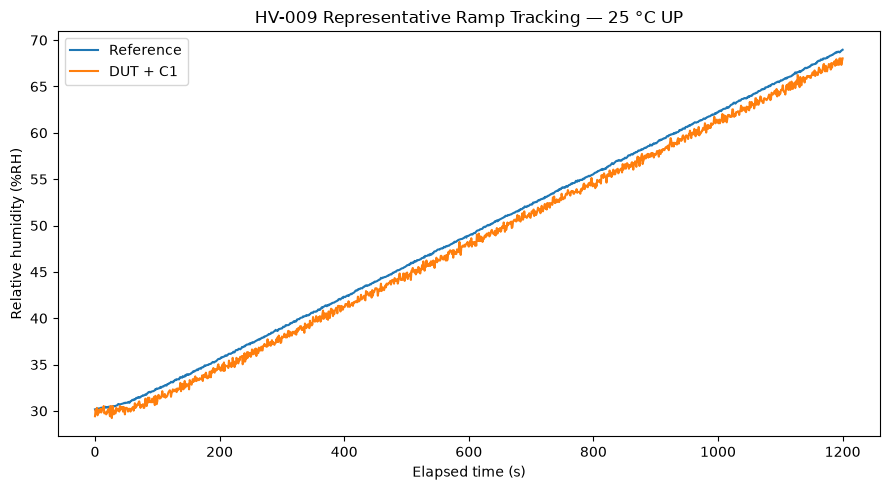

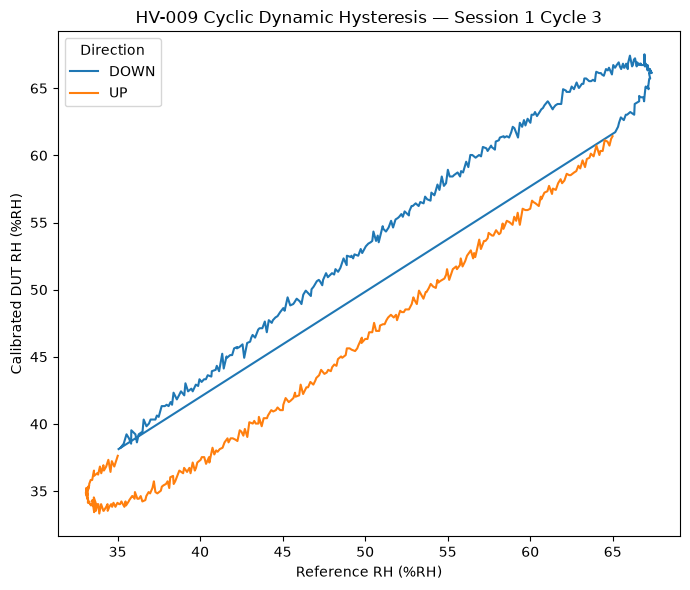

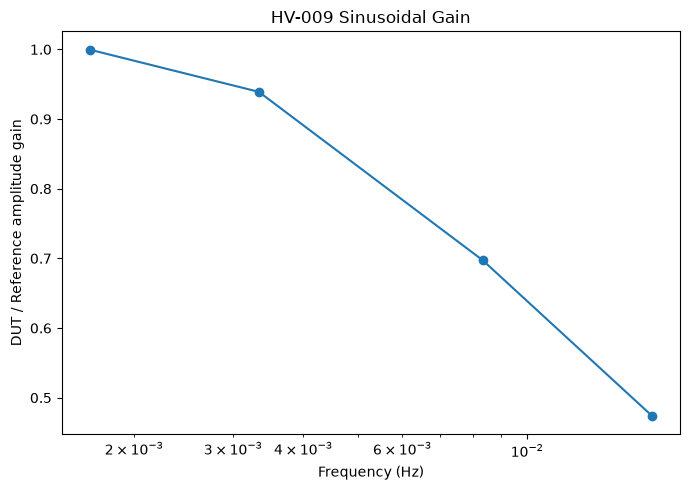

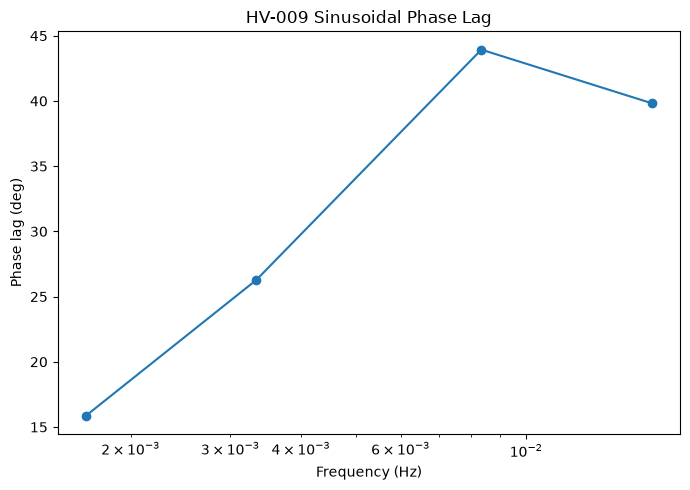

Curated HV-009 figures exported.


In [8]:
# Ramp example: 25 °C, UP, repetition 1
ramp_id = ramp_metrics_df.loc[
    (ramp_metrics_df["Temperature_Setpoint_C"] == 25.0)
    & (ramp_metrics_df["Direction"] == "UP")
    & (ramp_metrics_df["Repetition"] == 1),
    "Test_ID",
].iloc[0]

ramp_example = ramp_df.loc[ramp_df["Test_ID"] == ramp_id].sort_values("Elapsed_s").copy()
ramp_example["RH_DUT_C1"] = ramp_example["RH_DUT"] + frozen_c1_offset

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ramp_example["Elapsed_s"], ramp_example["RH_Reference"], label="Reference")
ax.plot(ramp_example["Elapsed_s"], ramp_example["RH_DUT_C1"], label="DUT + C1")
ax.set_xlabel("Elapsed time (s)")
ax.set_ylabel("Relative humidity (%RH)")
ax.set_title("HV-009 Representative Ramp Tracking — 25 °C UP")
ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / "hv009_ramp_tracking_example.png", dpi=160, bbox_inches="tight")
plt.show()

# Cyclic example: Session 1, Cycle 3
cyc = cyclic_df.loc[
    (cyclic_df["Session"] == 1) & (cyclic_df["Cycle_Index"] == 3)
].copy()
cyc["RH_DUT_C1"] = cyc["RH_DUT"] + frozen_c1_offset

fig, ax = plt.subplots(figsize=(7, 6))
for direction, group in cyc.groupby(cyc["Direction"].astype(str).str.upper()):
    ax.plot(
        group["RH_Reference"],
        group["RH_DUT_C1"],
        label=direction,
    )
ax.set_xlabel("Reference RH (%RH)")
ax.set_ylabel("Calibrated DUT RH (%RH)")
ax.set_title("HV-009 Cyclic Dynamic Hysteresis — Session 1 Cycle 3")
ax.legend(title="Direction")
fig.tight_layout()
fig.savefig(figures_dir / "hv009_cyclic_hysteresis_example.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(
    sinusoidal_response_df["Frequency_Hz"],
    sinusoidal_response_df["Gain"],
    marker="o",
)
ax.set_xscale("log")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("DUT / Reference amplitude gain")
ax.set_title("HV-009 Sinusoidal Gain")
fig.tight_layout()
fig.savefig(figures_dir / "hv009_sinusoidal_gain.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(
    sinusoidal_response_df["Frequency_Hz"],
    sinusoidal_response_df["Phase_Lag_Deg"],
    marker="o",
)
ax.set_xscale("log")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Phase lag (deg)")
ax.set_title("HV-009 Sinusoidal Phase Lag")
fig.tight_layout()
fig.savefig(figures_dir / "hv009_sinusoidal_phase_lag.png", dpi=160, bbox_inches="tight")
plt.show()

print("Curated HV-009 figures exported.")

## 10. Curated Evidence Export

In [9]:
ramp_metrics_df.to_csv(
    tables_dir / "hv009_ramp_test_metrics.csv",
    index=False,
)
ramp_summary_df.to_csv(
    tables_dir / "hv009_ramp_summary_by_condition.csv",
    index=False,
)
cyclic_cycle_df.to_csv(
    tables_dir / "hv009_cyclic_cycle_metrics.csv",
    index=False,
)
cyclic_session_df.to_csv(
    tables_dir / "hv009_cyclic_session_summary.csv",
    index=False,
)
sinusoidal_response_df.to_csv(
    tables_dir / "hv009_sinusoidal_frequency_response.csv",
    index=False,
)

print("Curated HV-009 tables exported.")

Curated HV-009 tables exported.


## 11. Initial DT-001 Checkpoint

A clean-kernel Run All should establish:

- DT-01 dataset boundary audit PASS;
- DT-02 frozen C1 verification PASS;
- DT-03 ramp Test_ID metrics PASS;
- DT-04 ramp summaries PASS;
- DT-05 cyclic metrics PASS;
- DT-06 sinusoidal frequency response PASS;
- five curated CSV tables;
- four curated figures.

The next step is engineering interpretation and formal DT-001 gate closure.

## 12. Engineering Interpretation

### 12.1 Ramp tracking — frozen C1 is not direction-neutral under dynamics

Mean ramp RMSE by Direction:

```text
DOWN:
Raw RMSE = 0.3241 %RH
C1 RMSE  = 1.3175 %RH

UP:
Raw RMSE = 2.3297 %RH
C1 RMSE  = 1.1248 %RH
```

Therefore:

- C1 improves UP ramp RMSE by approximately **51.7%**;
- C1 worsens DOWN ramp RMSE by approximately **306.5%**.

This is a critical dynamic result.

The frozen static offset is helpful when the DUT dynamically reads low during UP tracking, but the same positive offset over-corrects DOWN tracking where the raw DUT is already much closer to the reference.

The remaining C1 mean directional biases are:

```text
DOWN MBE = +1.2821 %RH
UP MBE   = -1.0833 %RH
```

The separation is approximately **2.3654 %RH**.

The temperature-aggregated C1 MBE values are small (+0.1396, +0.1290, +0.0297 %RH), but this should **not** be interpreted as good unbiased dynamic tracking. Those small marginal means mainly arise because positive DOWN bias and negative UP bias cancel when directions are pooled.

Thus Direction dominates Temperature for ramp tracking.

### 12.2 Cyclic response — large, highly repeatable dynamic hysteresis

Across the three sessions, mean C1 direction gap is approximately:

```text
Session 1: -4.6900 %RH
Session 2: -4.6866 %RH
Session 3: -4.6995 %RH
```

This is a large and highly consistent dynamic hysteresis/state effect.

Cycle 1 is visibly different from later cycles:

- Cycle-1 direction gap is approximately -5.22 to -5.24 %RH;
- Cycles 2–5 settle near approximately -4.54 to -4.58 %RH.

Across all sessions, considering cycles 2–5 only:

```text
Mean direction gap ≈ -4.5569 %RH
SD direction gap   ≈ 0.0125 %RH
Mean C1 RMSE       ≈ 2.9851 %RH
SD C1 RMSE         ≈ 0.0073 %RH
```

This indicates extremely strong repeatability after the first-cycle conditioning effect.

The positive MBE drift slopes of approximately +0.07 %RH/cycle and small negative RMSE slopes around -0.012 to -0.015 %RH/cycle are therefore interpreted primarily as a **first-cycle conditioning/startup effect**, not evidence of continuing monotonic drift across cycles 2–5.

Long-term drift is evaluated separately in HV-010.

### 12.3 Sinusoidal response — clear low-pass behavior relative to the measured reference

Frequency response:

```text
0.001667 Hz: Gain 0.9996, Phase lag 15.86°, time lag 26.44 s
0.003333 Hz: Gain 0.9390, Phase lag 26.27°, time lag 21.89 s
0.008333 Hz: Gain 0.6974, Phase lag 43.94°, time lag 14.65 s
0.016667 Hz: Gain 0.4741, Phase lag 39.83°, time lag  6.64 s
```

The DUT therefore tracks the measured reference almost one-for-one at the lowest tested frequency, but increasingly attenuates faster humidity variation.

At the highest tested frequency, the DUT reproduces only about **47%** of the reference amplitude.

The phase lag is also substantial. Equivalent time lag is not constant with frequency, indicating that the DUT behavior is not well represented as a pure fixed time delay; it behaves as a dynamic filtering system.

The measured reference amplitude itself also decreases with frequency, from approximately 9.48 %RH at 0.001667 Hz to 2.57 %RH at 0.016667 Hz. Therefore chamber/reference dynamics already attenuate the commanded excitation. The reported DUT gain is relative to that measured reference and isolates the additional DUT attenuation.

### 12.4 Consistency with HV-008

HV-008 showed:

- t90 around 104 s for DOWN;
- t90 around 120 s for UP;
- substantial DUT lag relative to the measured reference.

HV-009 is consistent with that slow response:

- ramp tracking shows direction-dependent dynamic error;
- cyclic tests show large repeatable dynamic hysteresis;
- sinusoidal tests show increasing attenuation and phase lag as excitation frequency increases.

These are three different manifestations of the same underlying dynamic limitation: the DUT cannot follow faster RH changes without direction-dependent lag and attenuation.

## 13. DT-001 Gate Decision

**DT-001 = PASS WITH DOCUMENTED CONDITIONS**

### Basis for PASS

- all Ramp, Cyclic, and Sinusoidal data boundaries are verified;
- frozen C1 is loaded unchanged;
- ramp tracking metrics are computed per Test_ID;
- cycle-level repeatability, Direction gap, and descriptive drift are quantified;
- sinusoidal gain and phase/time lag are extracted at all four frequencies;
- results are physically coherent and consistent with HV-008 step-response behavior.

### Documented conditions

1. **Ramp direction dependence:** C1 improves UP tracking but materially degrades DOWN tracking.
2. **Dynamic hysteresis:** cyclic Direction gap is large, approximately -4.69 %RH, and highly repeatable.
3. **First-cycle conditioning:** cycle 1 differs from cycles 2–5; apparent session drift slopes are dominated by this startup effect.
4. **Frequency attenuation:** DUT/reference gain falls from approximately 1.00 at 0.001667 Hz to approximately 0.47 at 0.016667 Hz.
5. **Phase lag:** substantial frequency-dependent phase lag remains.
6. **Calibration scope:** the frozen C1 static offset is not a dynamic compensation model and is not retuned here.
7. **No external dynamic acceptance threshold:** this milestone characterizes performance but does not establish final application suitability.

The next engineering stage is:

```text
HV-010 — Stability & Drift
```